In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

In [41]:
#styling
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

mpl.rcParams['figure.constrained_layout.use'] = True

In [42]:
df = pd.read_csv('data/TOI519_LC_MuSCAT_z-band.csv')
#df

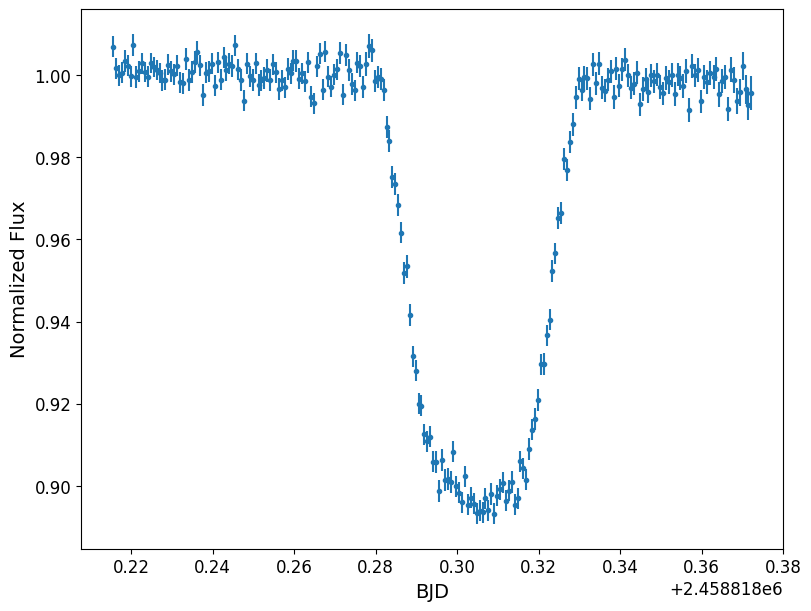

In [51]:
time = np.array(df['BJD'])
flux = np.array(df['Flux'])
err = np.array(df['Err'])

f = pl.figure(figsize=(8, 6))

pl.errorbar(time, flux, err, fmt='.')
pl.xlabel('BJD')
pl.ylabel('Normalized Flux')
#f.savefig('output/TOI519_transit_white.pdf')

# imput parameters

initial guess values from Parviainen et al. (2021)

In [52]:
from uncertainties import ufloat

k_pr = ufloat(0.3, 0.0091) #Rp/Rs
a_pr = ufloat(10.11, 0.14) #a/Rs
b_pr = ufloat(0.19, 0.06)  #impact parameter, b
T0_pr  = ufloat(2458491.8771169, 0.)   #Transit center T0
P_pr    =  ufloat(1.2652328, 0.0000005) #Orbital Period

In [53]:
num = np.ceil((df['BJD'][0] - T0_pr.n)/P_pr.n) #Transit number from T0
Tc_pr = T0_pr + num * P_pr  #Predicted transit center time for this transit
Tc_pr

2458818.3071793+/-0.000129

limb darkening prediction

In [54]:
from ldtk import LDPSetCreator
from ldtk.filters import sdss_z

teff, uteff = 3324,  157
feh, ufeh   = 0.0,  0.7 
logg,ulogg = 4.86877, 0.000630214

In [55]:
sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), filters=[sdss_z])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

In [56]:
u1, u2 = list(qd_c[0])
u1_err, u2_err = list(qd_e[0])

# Transit Model

In [57]:
import batman
def transit_model(parameters, period, u1,u2, t):

    tc,a,b,k=parameters
    inc= np.arccos(b/a)*180/np.pi
    
    params = batman.TransitParams()
    params.t0 = tc                      #time of inferior conjunction
    params.per = period                     #orbital period
    params.rp = k                 #planet radius (in units of stellar radii)
    params.a = a                      #semi-major axis (in units of stellar radii)
    params.inc = inc                     #orbital inclination (in degrees)
    params.ecc = 0.                      #eccentricity
    params.w = 0.                       #longitude of periastron (in degrees)
    params.u = [u1, u2]                #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  

    flux = m.light_curve(params)
    
    return flux

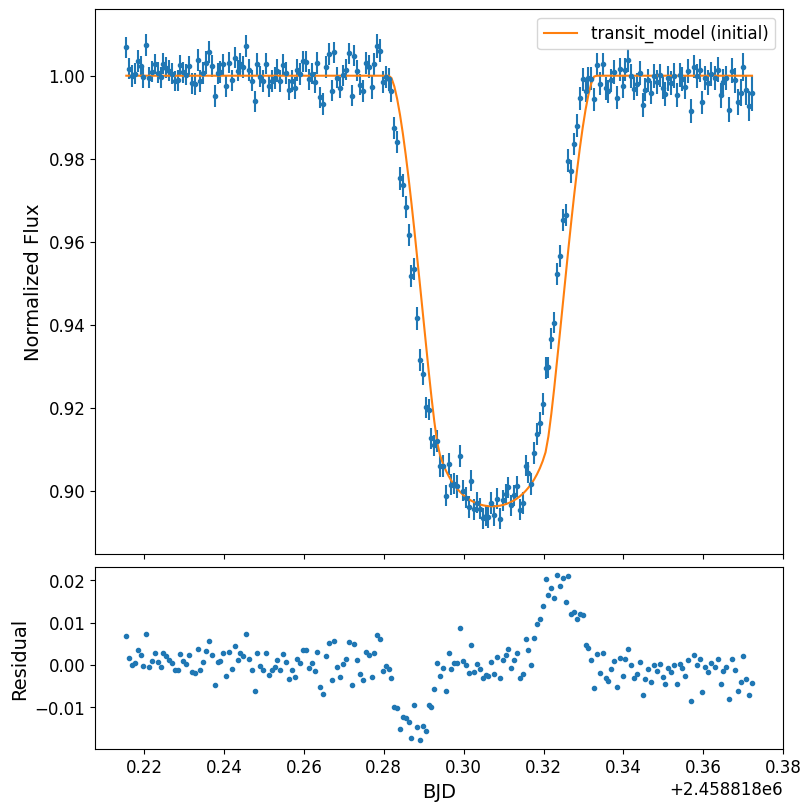

In [59]:
transit_params_init=[Tc_pr.n,a_pr.n,b_pr.n,k_pr.n]
transit_model_init=transit_model(transit_params_init, P_pr.n, u1, u2, time)

resid = flux - transit_model_init

f, axs = pl.subplots(2, 1, figsize=(8, 8), height_ratios=(3,1), sharex=True)

axs[0].errorbar(time,flux,err, fmt='.')
axs[0].plot(time,transit_model_init,label='transit_model (initial)')

axs[1].plot(time, resid, '.')

axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
axs[1].set_ylabel('Residual')
axs[0].legend()
#f.savefig('output/TOI519_transit_predict.pdf')

# Simple baseline model 


In [60]:
def base_model(base_params, t):
    w0, w1, w2 = base_params
    return  [w0]*len(t) + w1*(t-t[0])+ w2*(t-t[0])**2

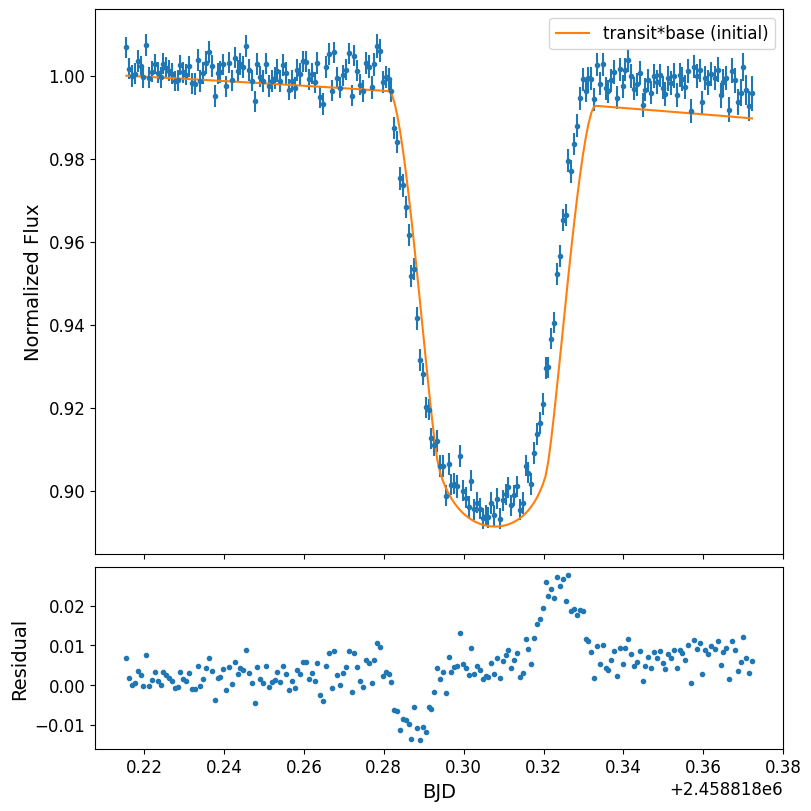

In [62]:
base_params_init = [1., -0.05, -0.1]
base_model_init = base_model(base_params_init,time)

combined_model_init = transit_model_init * base_model_init

resid = flux - combined_model_init

f, axs = pl.subplots(2, 1, figsize=(8, 8), height_ratios=(3,1), sharex=True)

axs[0].errorbar(time,flux,err, fmt='.')
axs[0].plot(time,combined_model_init, label='transit*base (initial)')

axs[1].plot(time, resid, '.')

axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
axs[1].set_ylabel('Residual')
axs[0].legend()

f.savefig('output/TOI519_transit_base_predict.pdf')

# preparing parameter set

In [81]:
params_full_init = transit_params_init + base_params_init
params_name = 'Tc,a_Rs,b,Rp_Rs,w0,w1,w2'.split(',')
#params_full_pr

# fitting

In [82]:
from scipy import stats

def logprior(params_full, time): #log-prior
    
    transit_params=params_full[:4]
    Tc, a, b, k = transit_params
    
    #Uniform priors
    if not (time[0]<Tc<time[-1]):
        return -np.inf
    
    if not 0<k<1:
        return -np.inf
    
    #Normal Priors
    lp = 0
    
    lp += stats.norm.logpdf(a, loc=a_pr.n, scale=a_pr.s)
    lp += stats.norm.logpdf(b, loc=b_pr.n, scale=b_pr.s)
    
    return lp

def loglike(flux,err,model): #log-likelihood
    residual = flux - model
    return -0.5 * np.sum((residual/err)**2)

def logprob(params_full, u1, u2, time, flux, err):  #log-posterior probability

    transit_params=params_full[:4]
    base_params=params_full[4:]
    
    tm = transit_model(transit_params, P_pr.n, u1,u2, time)
    sm = base_model(base_params,time)
    
    ll = loglike(flux, err, tm*sm)
    lp = logprior(params_full, time)
    
    return ll+lp

In [83]:
logprob(params_full_init, u1, u2, time, flux, err)

-1080.955364347114

# Optimization

In [84]:
import scipy.optimize as op

def neg_logprob(params_full, u1, u2, time, flux, err):
    return -logprob(params_full, u1, u2, time, flux, err)

result = op.minimize(neg_logprob, params_full_init, args=(u1, u2, time, flux, err),method='Powell')

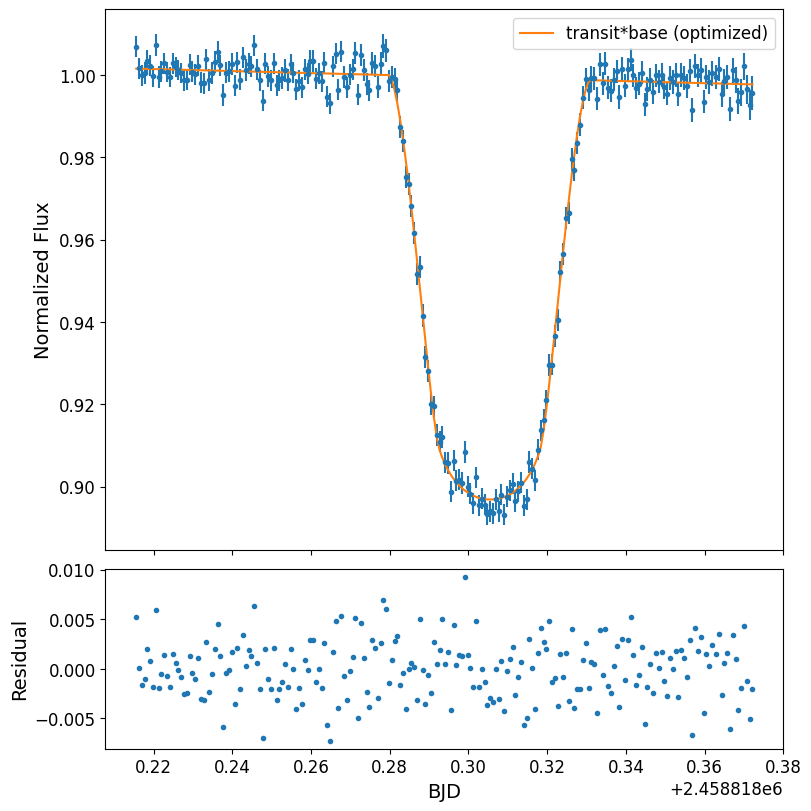

In [85]:
transit_params_opt=result.x[:4]
base_params_opt=result.x[4:]

transit_model_opt=transit_model(transit_params_opt, P_pr.n, u1,u2, time)
base_model_opt = base_model(base_params_opt,time)

combined_model_opt = transit_model_opt * base_model_opt

resid = flux - combined_model_opt

f, axs = pl.subplots(2, 1, figsize=(8, 8), height_ratios=(3,1), sharex=True)

axs[0].errorbar(time,flux,err, fmt='.')
axs[0].plot(time,combined_model_opt, label='transit*base (optimized)')

axs[1].plot(time, resid, '.')

axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
axs[1].set_ylabel('Residual')
axs[0].legend()

f.savefig('output/TOI519_transit_base_opt.pdf')

# MCMC

In [86]:
import emcee

params  = result.x
ndim = len(params)
nwalkers = 64
nsteps=10000

In [87]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, logprob, args=(u1, u2, time, flux, err))

p0 = [params +  1e-5 * np.random.randn(ndim) for i in range(nwalkers)]
sampler.run_mcmc(p0, nsteps, progress=True)
samples = sampler.get_chain(discard=0, thin=1)

100%|███████████████████████████████████████| 10000/10000 [03:21<00:00, 49.72it/s]


In [88]:
print("Mean acceptance fraction: {0:.3f}".format(np.mean(sampler.acceptance_fraction)))
print("Mean autocorrelation time: {0:.3f} steps".format(np.mean(sampler.get_autocorr_time())))

Mean acceptance fraction: 0.485
Mean autocorrelation time: 74.311 steps


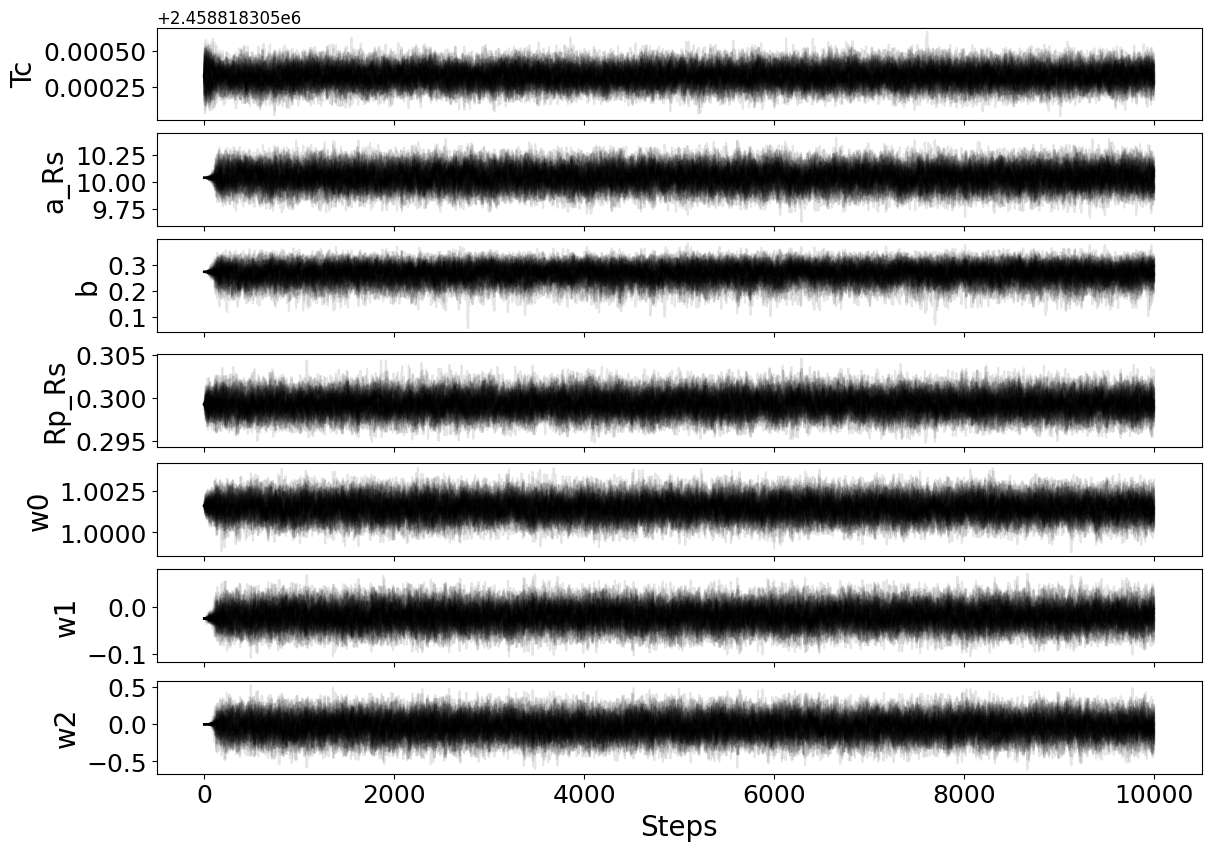

In [103]:
f, ax = pl.subplots(ndim, 1, figsize=(10*1.2,ndim*1.2))

for i in range(ndim):
    ax[i].plot(samples[:, :, i], color='k', alpha=0.1)
    
    if i==(ndim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)
    
f.savefig('output/TOI519_chain.png')

In [90]:
flat_samples = sampler.get_chain(discard=5000, thin=10, flat=True)

In [91]:
params_full_best=[]
params_full_best_err = []

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)

    params_full_best.append(mcmc[1])
    params_full_best_err.append(np.mean(q))

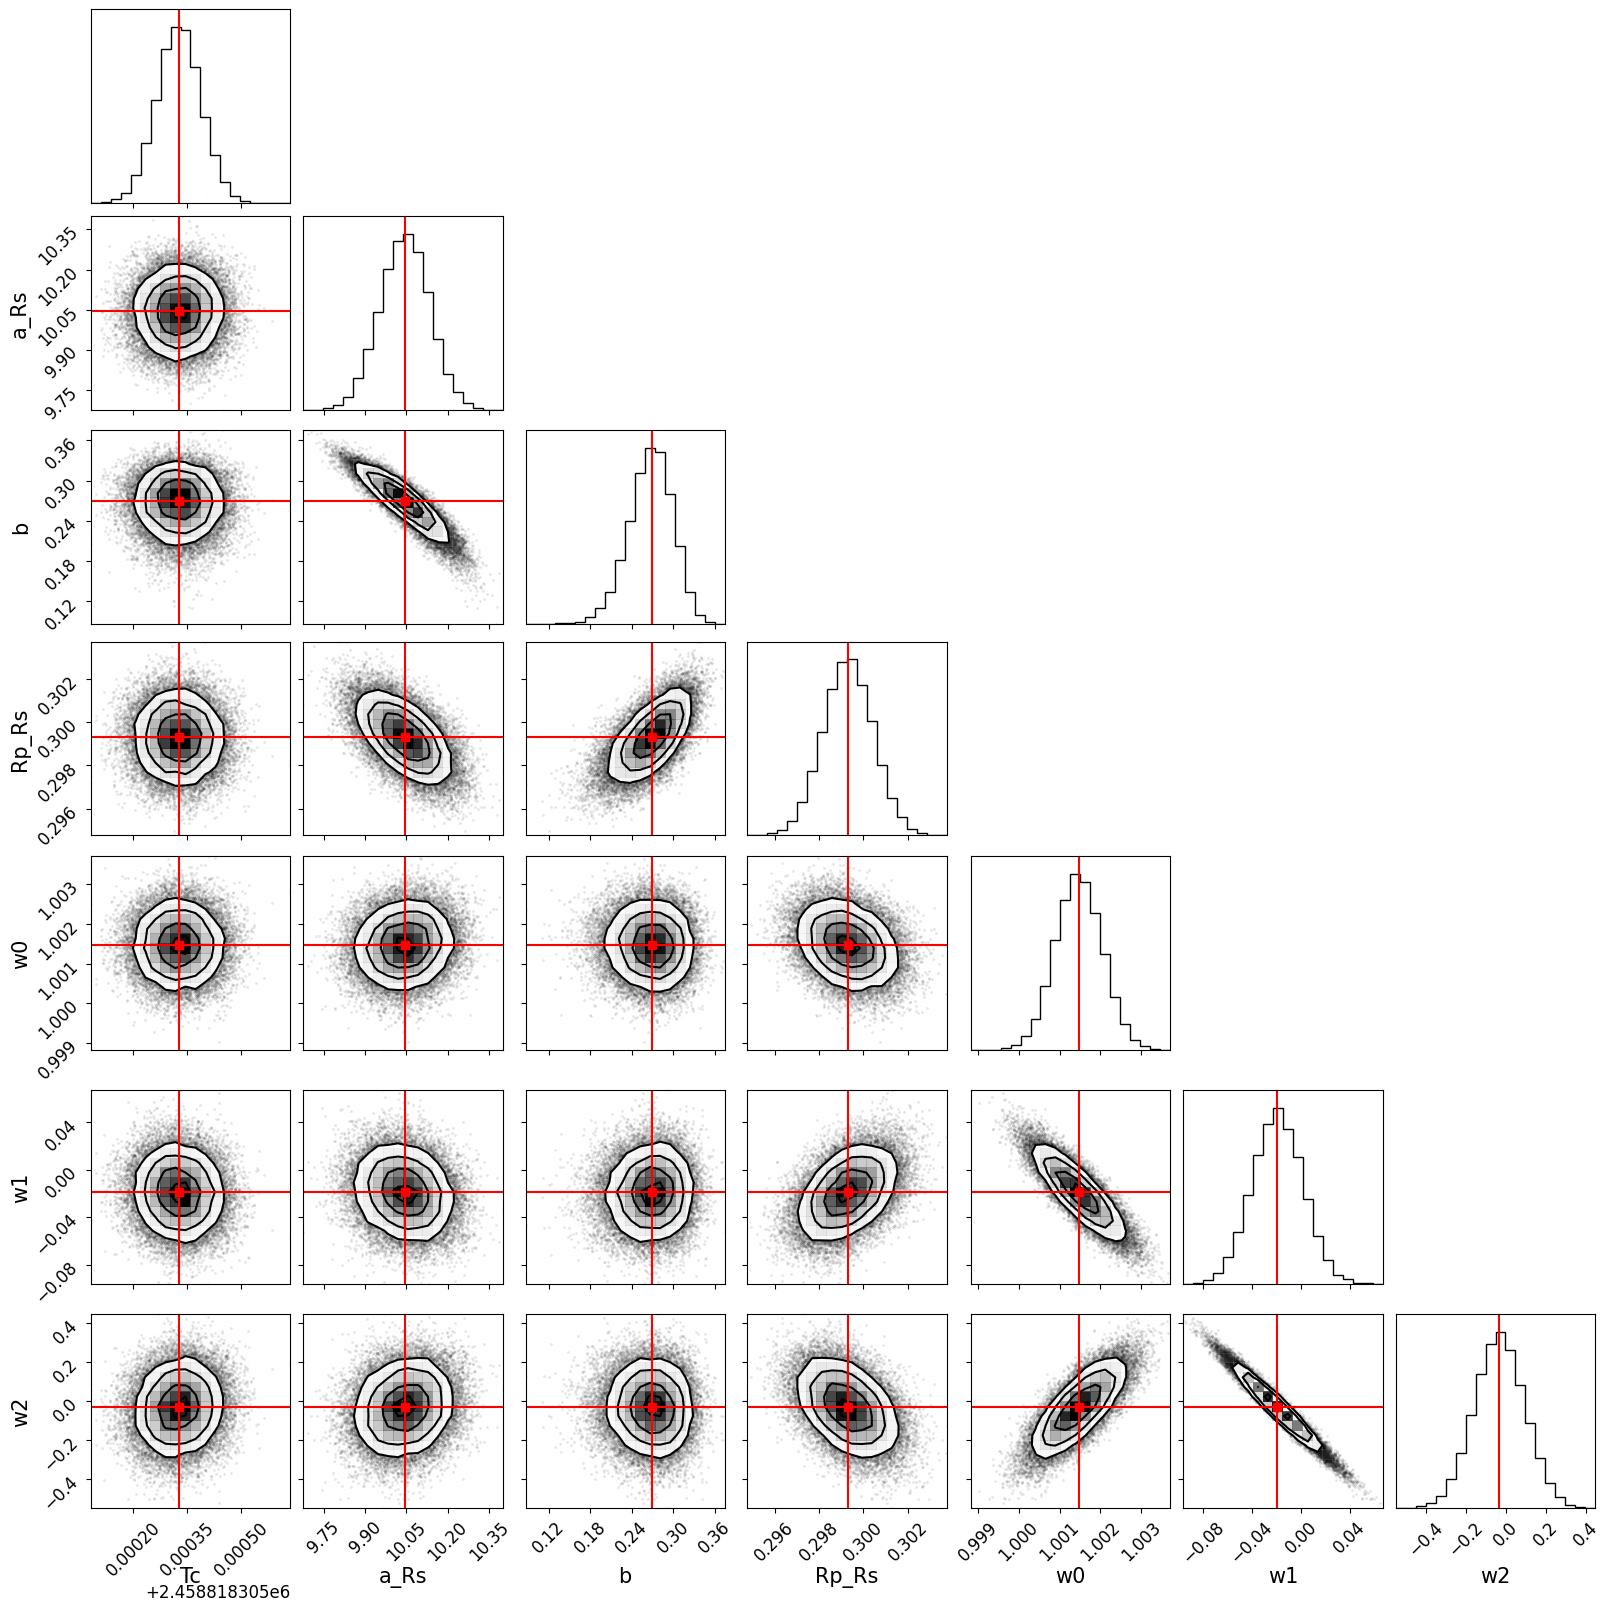

In [94]:
import corner

f = corner.corner(flat_samples, labels=params_name, label_kwargs=dict(fontsize=15))    
axes = np.array(f.axes).reshape((ndim, ndim))

# best parameters
for i in range(ndim):
    ax = axes[i, i]
    ax.axvline(params_full_best[i], color="r")

for yi in range(ndim):
    for xi in range(yi):
        ax = axes[yi, xi]     
        ax.axvline(params_full_best[xi], color="r")
        ax.axhline(params_full_best[yi], color="r")
        ax.plot(params_full_best[xi], params_full_best[yi], "sr")

f.savefig('output/TOI519_corner.pdf')

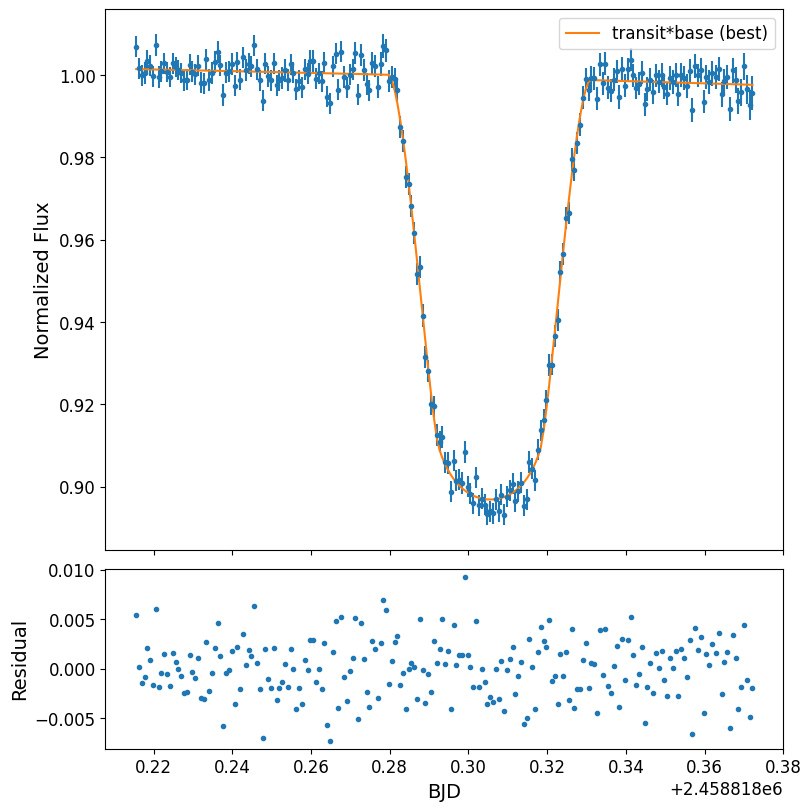

In [104]:
transit_params_best=params_full_best[:4]
base_params_best=params_full_best[4:]

transit_model_best=transit_model(transit_params_best, P_pr.n, u1, u2, time)
base_model_best = base_model(base_params_best,time)
combined_model_best = transit_model_best * base_model_best

resid = flux - combined_model_best

f, axs = pl.subplots(2, 1, figsize=(8, 8), height_ratios=(3,1), sharex=True)

axs[0].errorbar(time,flux,err, fmt='.')
axs[0].plot(time,combined_model_best, label='transit*base (best)')

axs[1].plot(time, resid, '.')

axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
axs[1].set_ylabel('Residual')
axs[0].legend()

f.savefig('output/TOI519_transit_base_best.pdf')

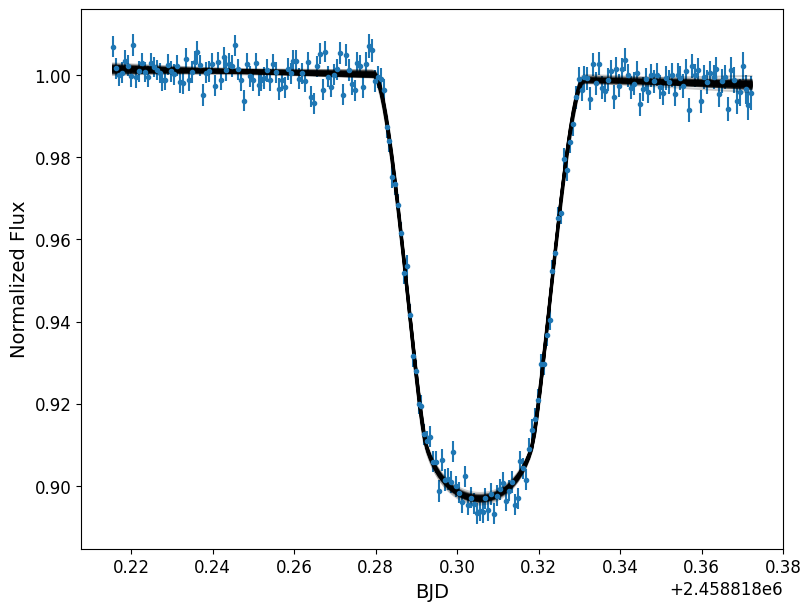

In [105]:
f=pl.figure(figsize=(8, 6))

pl.errorbar(time,flux,err, fmt='.', zorder=0)


for i in np.random.choice(np.arange(1, len(flat_samples)+1), size=100, replace=False):
    params_tmp = flat_samples[i]
    
    transit_params_tmp=params_tmp[:4]
    base_params_tmp=params_tmp[4:]

    transit_model_tmp=transit_model(transit_params_tmp, P_pr.n, u1, u2, time)
    base_model_tmp = base_model(base_params_tmp,time)
    
    pl.plot(time, transit_model_tmp * base_model_tmp, '-', alpha=0.2, color='k', zorder=0)    

pl.xlabel('BJD')
pl.ylabel('Normalized Flux')

f.savefig('output/TOI519_transit_base_100.pdf')